<a href="https://colab.research.google.com/github/nourswaid/movies-review-sentiment-analysis/blob/main/Movies_review_sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv('/content/IMDB Dataset.csv',  engine="python")

In [ ]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


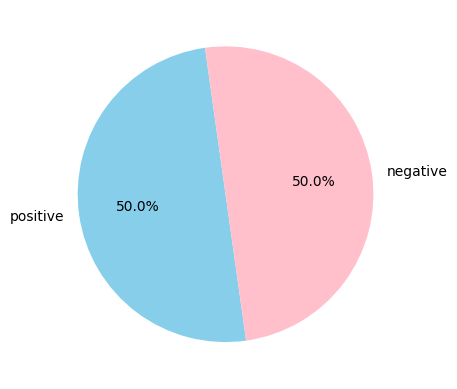

In [ ]:
x=df['sentiment'].value_counts()
plt.pie(x.values,labels=x.index,autopct='%1.1f%%',startangle=98,colors=['skyblue','pink'])
plt.show()

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
from nltk.stem import PorterStemmer


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
corpus=[]

for i in range(0,len(df)):
  review=re.sub('[^A-Za-z]',' ',df['review'][i])
  review=review.lower()
  review=review.split()
  all_stopwords=stopwords.words('english')
  all_stopwords.remove('not')
  ps=PorterStemmer()
  review=[ps.stem(word) for word in review if not word in set(all_stopwords)]

  review=' '.join(review)
  corpus.append(review)

In [ ]:
len(corpus)

50000

In [ ]:
# tokenaization using bag of words:

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
vc=CountVectorizer(max_features=5000)
x=vc.fit_transform(corpus).toarray()
y=df.iloc[:,-1].values

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
from sklearn.naive_bayes import GaussianNB
classifier=GaussianNB()
classifier.fit(x,y)

GaussianNB()

In [ ]:
prediction=classifier.predict(x_test)


In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
score=accuracy_score(y_test,prediction)
print(score)

0.7345


In [ ]:
from sklearn.svm import LinearSVC

classifier = LinearSVC()
classifier.fit(x_train, y_train)

y_pred = classifier.predict(x_test)
score=accuracy_score(y_test,y_pred)
print(score)

0.8616


In [ ]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(max_iter=1000)
classifier.fit(x_train, y_train)

y_pred = classifier.predict(x_test)
score=accuracy_score(y_test,y_pred)
print(score)

0.8713


<Axes: >

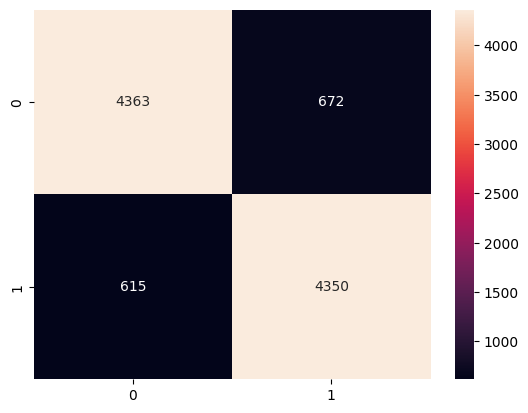

In [ ]:
#Logsitc regression confusion matrix & classificatio report
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm,annot=True,fmt='g')
